In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from cvxopt import matrix, solvers
import math
import matplotlib.pyplot as plt
from utils import *
from class_utils import *
from scipy.spatial.distance import cdist 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from collections import defaultdict
from random import sample
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from tqdm import trange, tqdm

In [2]:
df_spectra = pd.read_csv('spectral_data_all.csv')
df_spectra.drop(columns=['Unnamed: 0'], inplace=True)
df_spectra_flopp = df_spectra.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


In [3]:
df_spectra.groupby('data_source').count()

,wavelength,intensity,file_name,polymer,type_sprectra
data_source,,,,,
RDWP,243647,243647,243647,230975,243647
Rpackage,1237456,1237456,1237456,100804,1237456
flopp,347634,347634,347634,347634,347634
flopp_e,364455,364455,364455,364455,364455
food_packaging,172603,172603,172603,172603,172603
slopp,156315,156315,156315,156315,156315
slopp_e,133758,133758,133758,133758,133758


In [4]:
wl_list

Index([674.9918, 676.9203, 678.8489, 680.7775,  682.706, 684.6345, 686.5631,
       688.4916, 690.4202, 692.3488,
       ...
       3982.452,  3984.38, 3986.309, 3988.237, 3990.166, 3992.094, 3994.023,
       3995.951,  3997.88, 3999.809],
      dtype='object', name='wavelength', length=1725)

## Nylon
## Polyester
## Acrylic

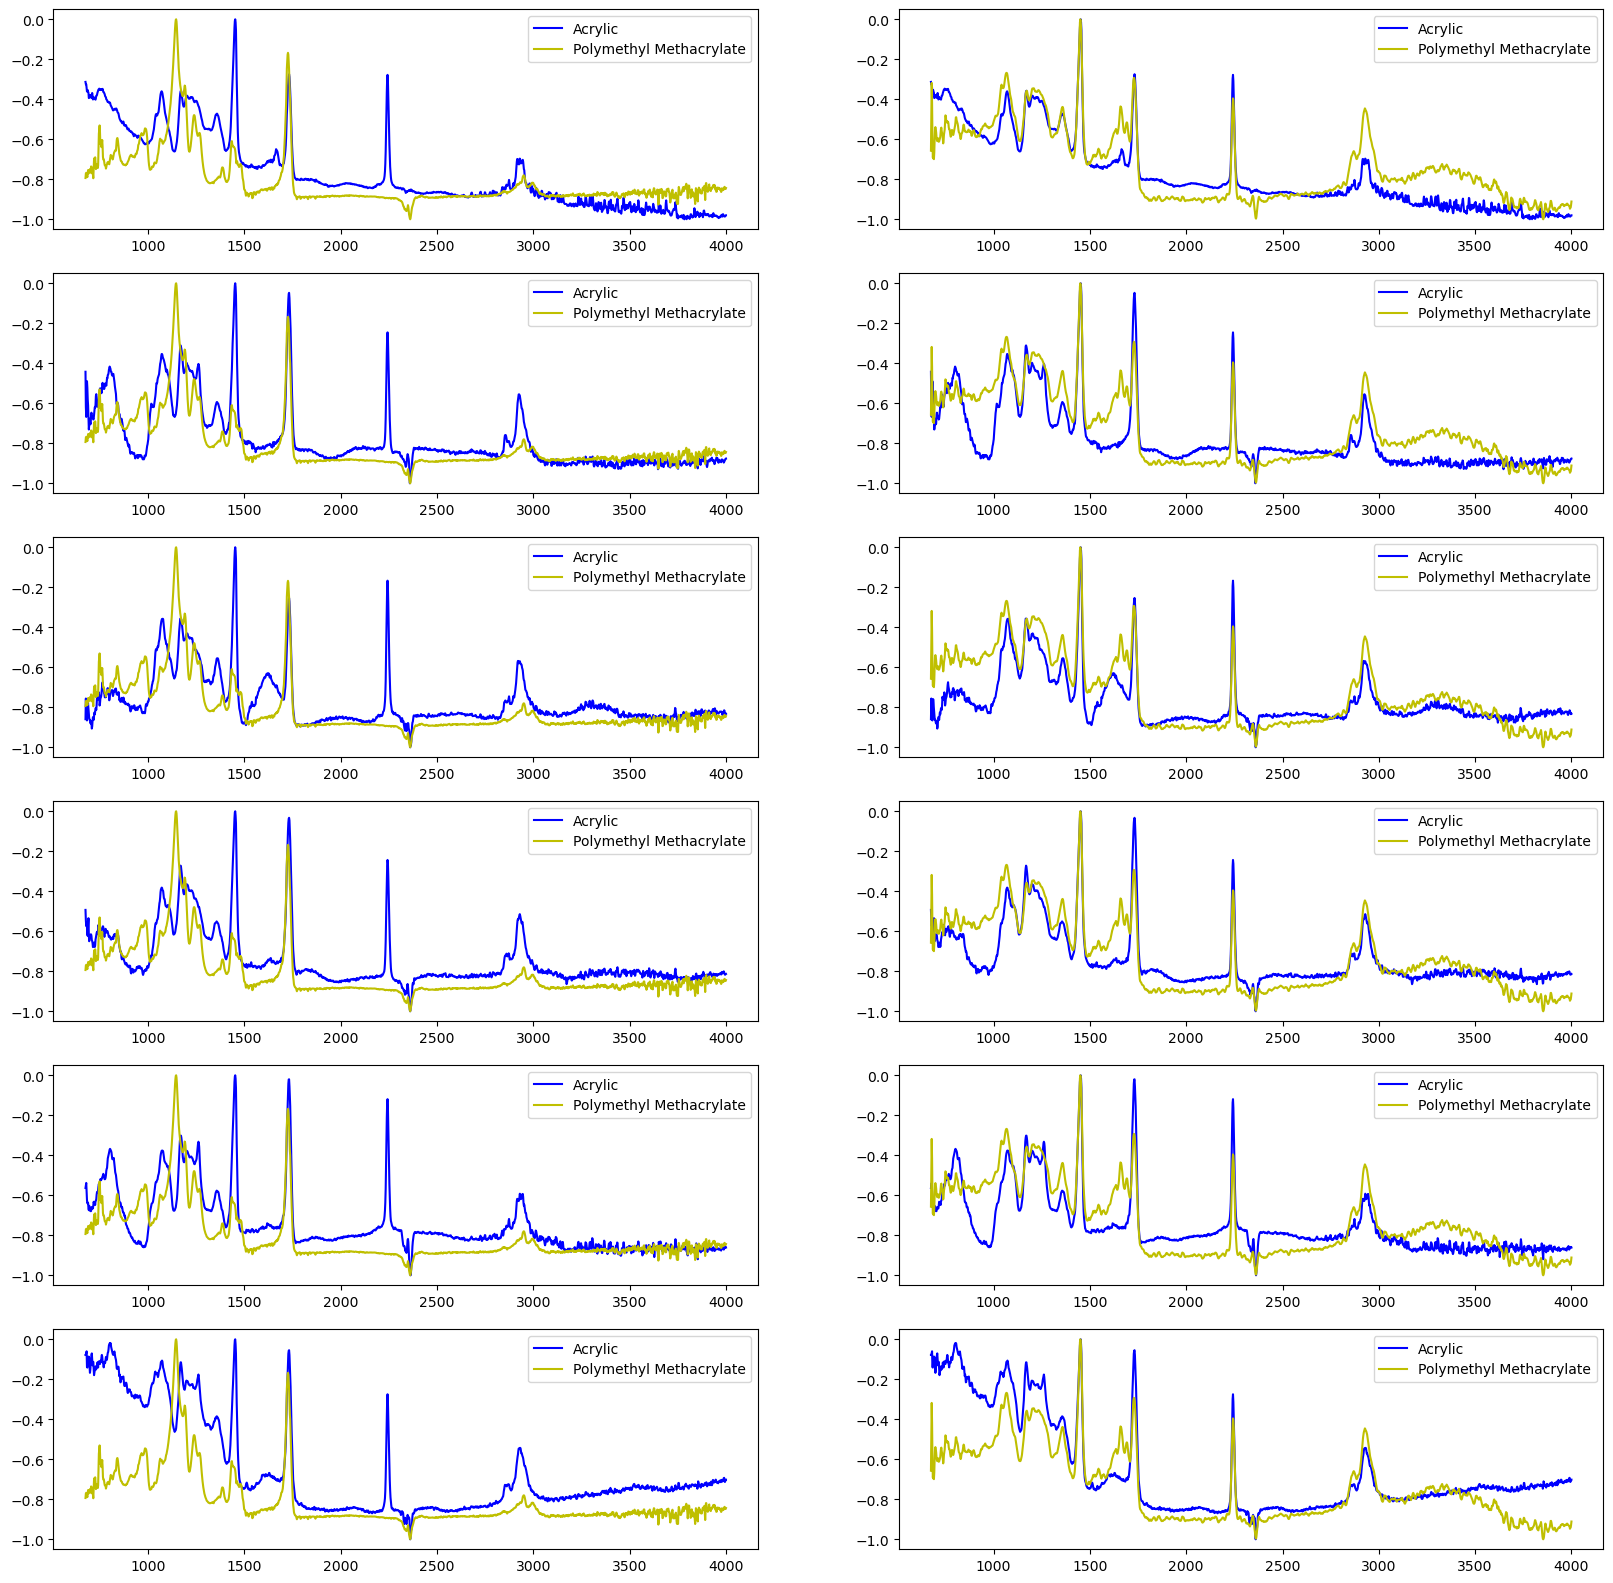

In [3]:
fig, ax = plt.subplots(nrows=6, ncols=2)
fig.set_figheight(20)
fig.set_figwidth(20)
df_fltered = df_spectra_flopp.query('polymer == "Acrylic"')
df_fltered2 = df_spectra_flopp.query('polymer == "Polymethyl Methacrylate"')
        #df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
file_name_list2 = df_fltered2['file_name'].drop_duplicates().to_numpy()
n_files = len(file_name_list)
n_files2 = len(file_name_list)
        
#if ds == 'flopp':
#color = 'y'
#else:
#color = 'b'

fn = file_name_list[5]
fn2 = file_name_list2[1]
        
for i, fn in enumerate(file_name_list):
    for j, fn2 in enumerate(file_name_list2):
        
        ax[i, j].plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

        ax[i, j].plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

        ax[i, j].legend()
        

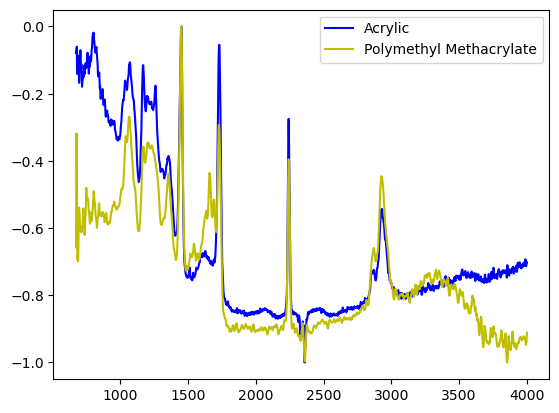

In [4]:
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

plt.legend()

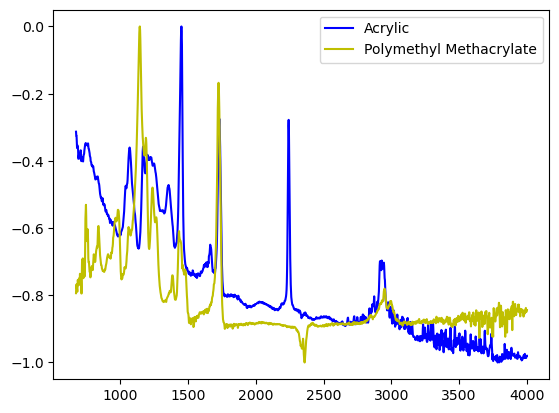

In [5]:
fn = file_name_list[0]
fn2 = file_name_list2[0]
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

plt.legend()

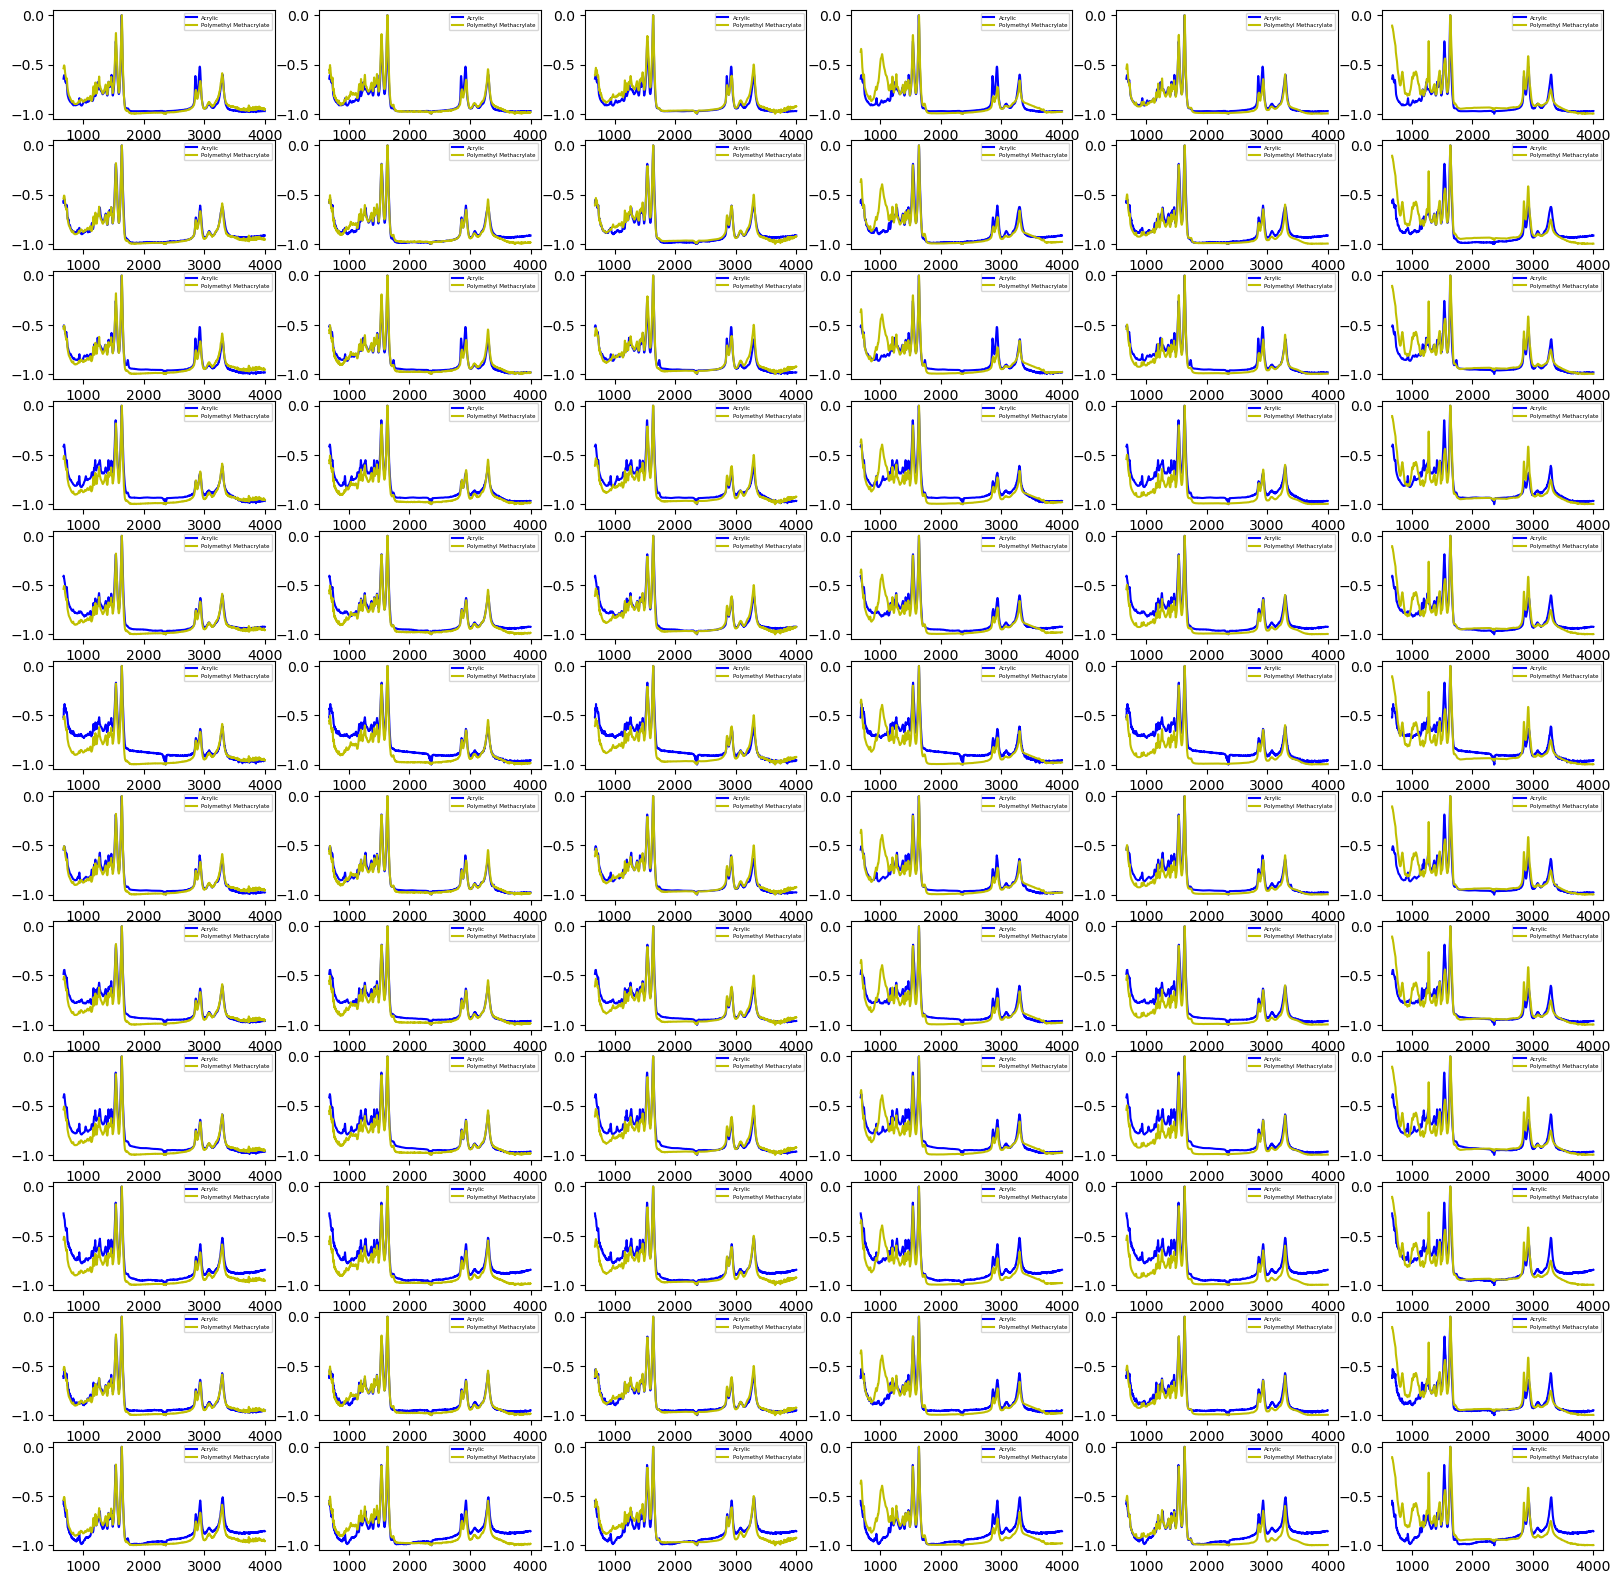

In [6]:
fig, ax = plt.subplots(nrows=12, ncols=6)
fig.set_figheight(20)
fig.set_figwidth(20)
df_fltered = df_spectra_flopp.query('polymer == "Nylon"')
df_fltered2 = df_spectra_flopp.query('polymer == "Polyamide"')
        #df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
file_name_list2 = df_fltered2['file_name'].drop_duplicates().to_numpy()
n_files = len(file_name_list)
n_files2 = len(file_name_list)
        
#if ds == 'flopp':
#color = 'y'
#else:
#color = 'b'

fn = file_name_list[5]
fn2 = file_name_list2[1]
        
for i, fn in enumerate(file_name_list):
    for j, fn2 in enumerate(file_name_list2):
        
        ax[i, j].plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Acrylic')

        ax[i, j].plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polymethyl Methacrylate')

        ax[i, j].legend(fontsize=4)
        

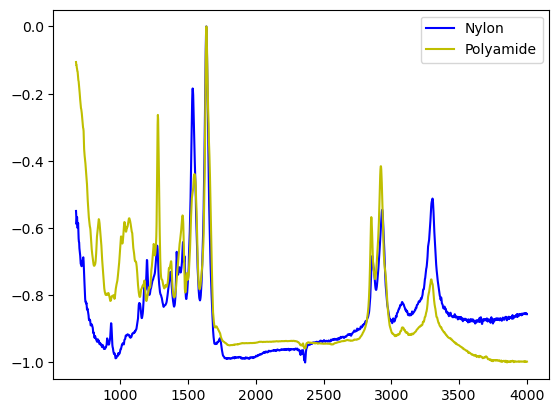

In [7]:
plt.plot(df_fltered.query('file_name == @fn')['wavelength'],
                 -df_fltered.query('file_name == @fn')['intensity'],
                 alpha=1,
                 color='b',
                 label='Nylon')

plt.plot(df_fltered2.query('file_name == @fn2')['wavelength'],
                 -df_fltered2.query('file_name == @fn2')['intensity'],
                 alpha=1,
                 color='y',
                 label='Polyamide')

plt.legend()

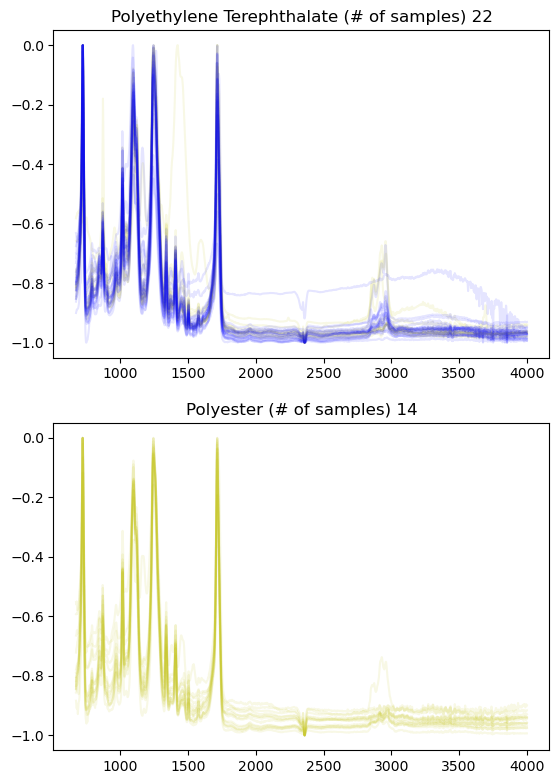

In [8]:
fig, ax = plt.subplots(nrows=2)
#fig.set_figheight(40)
#fig.set_figwidth(20)
for j, ds in enumerate(['flopp', 'flopp_e']):
    for i, p in enumerate(['Polyethylene Terephthalate', 'Polyester']):
        
        df_fltered = df_spectra_flopp.query('polymer == @p and data_source == @ds')
        df_fltered = df_fltered.query('wavelength > 674 and wavelength < 4000')
        file_name_list = df_fltered['file_name'].drop_duplicates().to_numpy()
        n_files = len(file_name_list)
        
        if ds == 'flopp':
            color = 'y'
        else:
            color = 'b'

        for fn in file_name_list:
            _ = ax[i].plot(df_fltered.query('file_name == @fn')['wavelength'],
                            -df_fltered.query('file_name == @fn')['intensity'],
                           alpha=0.1,
                           color=color)
            _ = ax[i].title.set_text(p + ' (# of samples) ' + str(n_files))
            #_ = ax[i, j].plot()
            #_ = ax[i, j].plot()
            #_ = ax[i, j].legend()
            #
        
fig.subplots_adjust(left=None, 
                            bottom=0, 
                            right=None, 
                            top=1.5, 
                            wspace=None, 
                            hspace=None)

In [5]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
n, p = x_train.shape

In [6]:
folds

[(array([  0,   1,   2,   4,   5,   6,   7,   8,   9,  10,  11,  13,  14,
          15,  16,  17,  19,  20,  21,  22,  23,  24,  25,  26,  27,  28,
          29,  30,  31,  32,  33,  34,  35,  36,  38,  39,  40,  41,  42,
          43,  44,  45,  46,  47,  48,  49,  50,  52,  53,  54,  55,  56,
          57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
          70,  71,  75,  76,  77,  78,  79,  80,  83,  84,  85,  86,  87,
          88,  89,  90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100,
         103, 104, 105, 106, 107, 109, 110, 111, 113, 114, 115, 116, 118,
         119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131,
         132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 144, 145,
         147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159,
         160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172,
         173, 174, 175, 176, 177, 180, 181, 182, 183, 184, 185]),
  array([  3,  12,  18,  37,  51,  72,  73,  7

In [13]:
clf = model_logReg(C=7)
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test)
clf.score(X_test, y_test)

0.8

In [11]:
y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                       'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table.loc[np.logical_not(np.isnan(pred_test_table['accurasy_test'])), :]#.query('accurasy_test > 0')
#pred_test_table

,count_train,count_test,accurasy_test
Acrylonitrile Butadiene Styrene,14.0,1.0,1.000000
Cotton,14.0,12.0,1.000000
Polycarbonate,8.0,1.0,1.000000
Polyethylene,18.0,49.0,0.918367
Polyethylene Terephthalate,11.0,22.0,0.409091
Polyethylene Vinyl Acetate,10.0,5.0,1.000000
Polypropylene,19.0,66.0,0.878788
Polystyrene,14.0,12.0,0.833333
Polyurethane,13.0,6.0,1.000000
Polyvinyl Chloride,9.0,9.0,1.000000


In [12]:
nan_train = np.logical_not(np.isnan(pred_test_table['count_train']))
(pred_test_table.loc[nan_train, 'count_test'] * 
 pred_test_table.loc[nan_train, 'accurasy_test']).sum() / pred_test_table.loc[nan_train, 'count_test'].sum()


0.8524590163934426

In [13]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
conf_mat = conf_mat - np.diag(np.diag(conf_mat))

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df['true_polymer'] = classes_test_hat
#conf_mat_df = conf_mat_df.reset_index()
conf_mat_df = conf_mat_df.melt(id_vars=['true_polymer'])
conf_mat_df.columns = ['true_polymer', 'pred_polymer', 'miss_class']
(conf_mat_df.
 query('miss_class > 0').
 merge(pred_test_table.loc[:,'count_test'], 
       left_on='true_polymer', 
       right_index=True).
 sort_values(['true_polymer', 'pred_polymer']))

,true_polymer,pred_polymer,miss_class,count_test
211,Cellulose Acetate,Polyethylene Vinyl Acetate,2,2.0
213,Ethylene Acrylic Acid,Polyethylene Vinyl Acetate,1,1.0
101,Polyamide,Nylon,6,6.0
66,Polyethylene,Cotton,1,49.0
294,Polyethylene,Polyurethane,1,49.0
332,Polyethylene,Rubber,2,49.0
162,Polyethylene Terephthalate,Polyester,13,22.0
12,Polymethyl Methacrylate,Acrylic,1,2.0
297,Polymethyl Methacrylate,Polyurethane,1,2.0
70,Polypropylene,Cotton,1,66.0


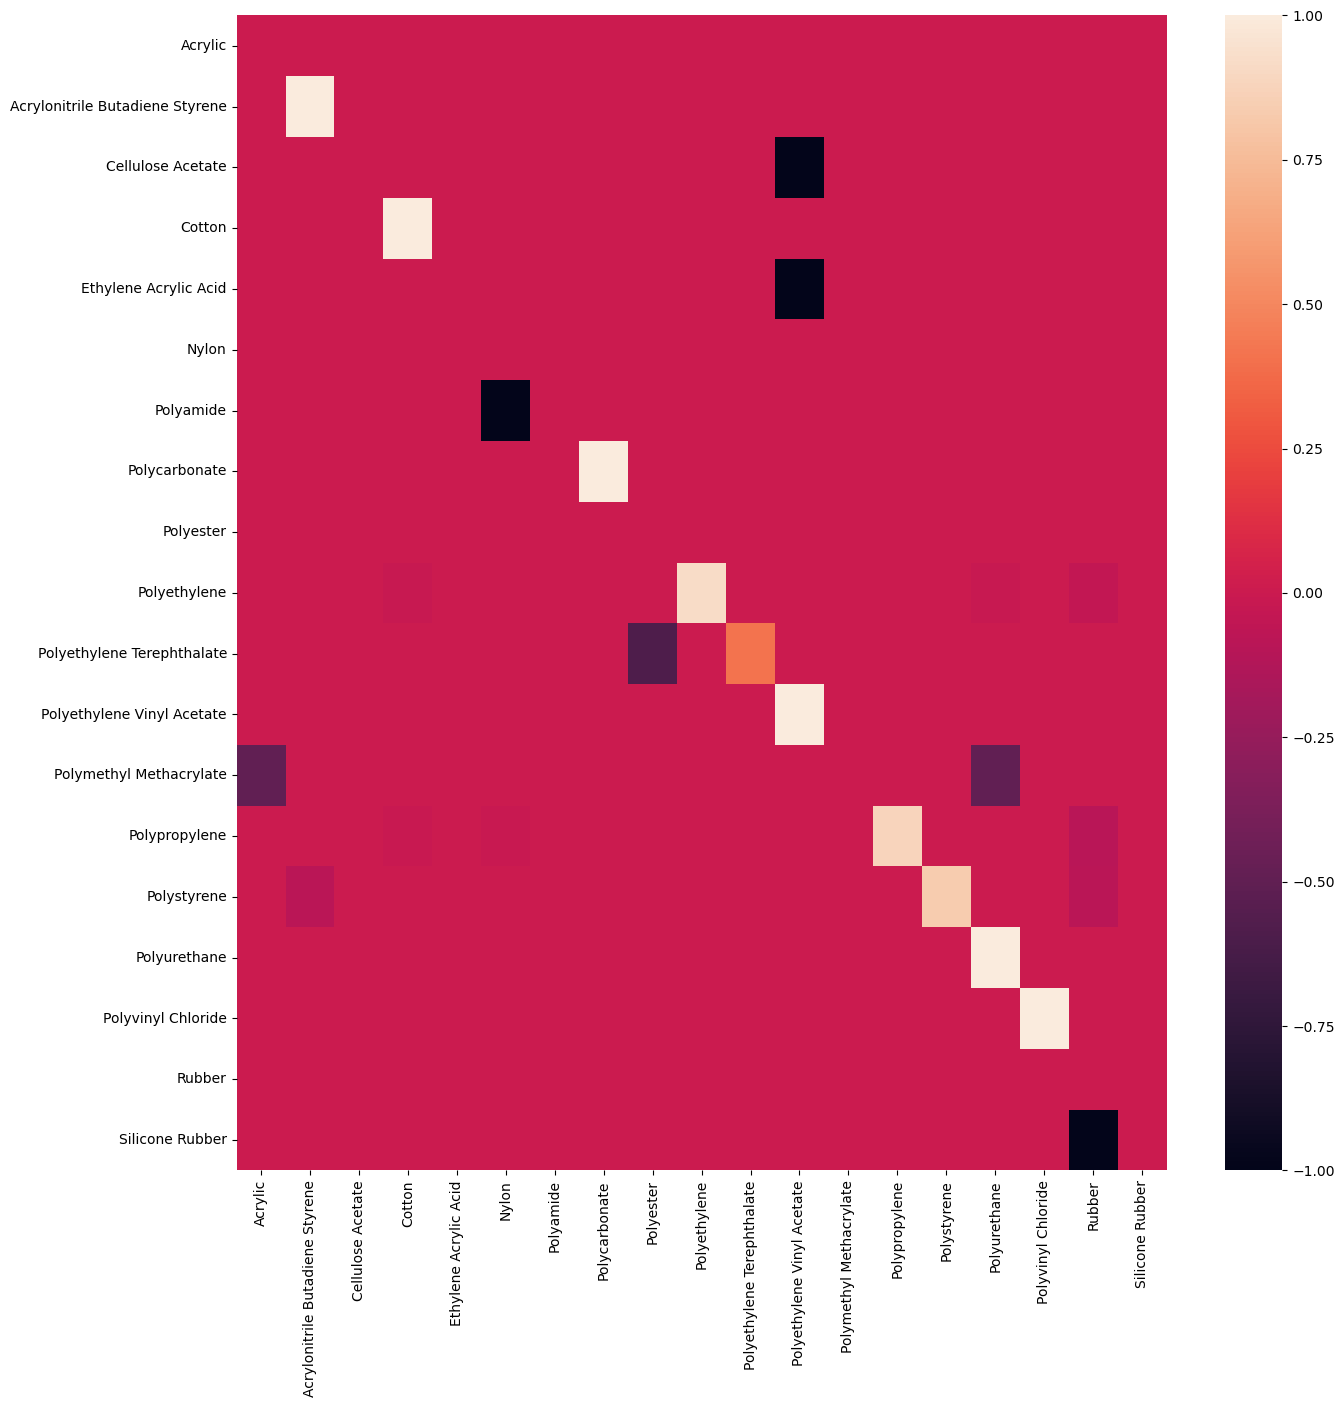

In [14]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [26]:
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
#y_train_[y_train_ == 'Acrylic'] = 'Polymethyl Methacrylate'

In [27]:
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
y_test_hat = clf.predict(X_test)
clf_score = clf.score(X_test, y_test)
clf_score

0.8871794871794871

best C: 1.00


(1.0, 0.9631578947368421)

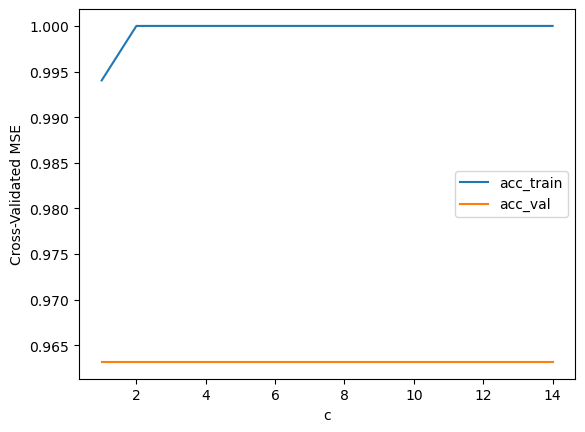

In [66]:
clf.cv(folds, list(range(1, 15)), plot_=True)

In [28]:
conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
conf_mat = conf_mat - np.diag(np.diag(conf_mat))

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df['true_polymer'] = classes_test_hat
#conf_mat_df = conf_mat_df.reset_index()
conf_mat_df = conf_mat_df.melt(id_vars=['true_polymer'])
conf_mat_df.columns = ['true_polymer', 'pred_polymer', 'miss_class']
(conf_mat_df.
 query('miss_class > 0').
 merge(pred_test_table.loc[:,'count_test'], 
       left_on='true_polymer', 
       right_index=True).
 sort_values(['true_polymer', 'pred_polymer']))

NameError: name 'classes_test_hat' is not defined

In [29]:
y_train_df = pd.DataFrame(y_train)
y_train_df['count'] = 1
classes_count_train = y_train_df.groupby('polymer').count()

pred_test = pd.DataFrame({'true_poly': np.asarray(y_test), 
                       'correct_class':y_test_hat == np.asarray(y_test)})

pred_test_table = pd.concat([classes_count_train,
           pred_test.groupby('true_poly').count(),
           pred_test.groupby('true_poly').mean()], axis=1)

pred_test_table.columns = ['count_train', 'count_test', 'accurasy_test']
pred_test_table.loc[np.logical_not(np.isnan(pred_test_table['accurasy_test'])), :]#.query('accurasy_test > 0')

,count_train,count_test,accurasy_test
Acrylonitrile Butadiene Styrene,14.0,1.0,1.000000
Cotton,14.0,12.0,1.000000
Polyamide,12.0,6.0,1.000000
Polycarbonate,8.0,1.0,1.000000
Polyethylene,18.0,49.0,0.897959
Polyethylene Terephthalate,25.0,22.0,1.000000
Polyethylene Vinyl Acetate,10.0,5.0,1.000000
Polypropylene,19.0,66.0,0.878788
Polystyrene,14.0,12.0,0.833333
Polyurethane,13.0,6.0,1.000000


In [30]:
nan_train = np.logical_not(np.isnan(pred_test_table['count_train']))
(pred_test_table.loc[nan_train, 'count_test'] * 
 pred_test_table.loc[nan_train, 'accurasy_test']).sum() / pred_test_table.loc[nan_train, 'count_test'].sum()

0.9153439153439153

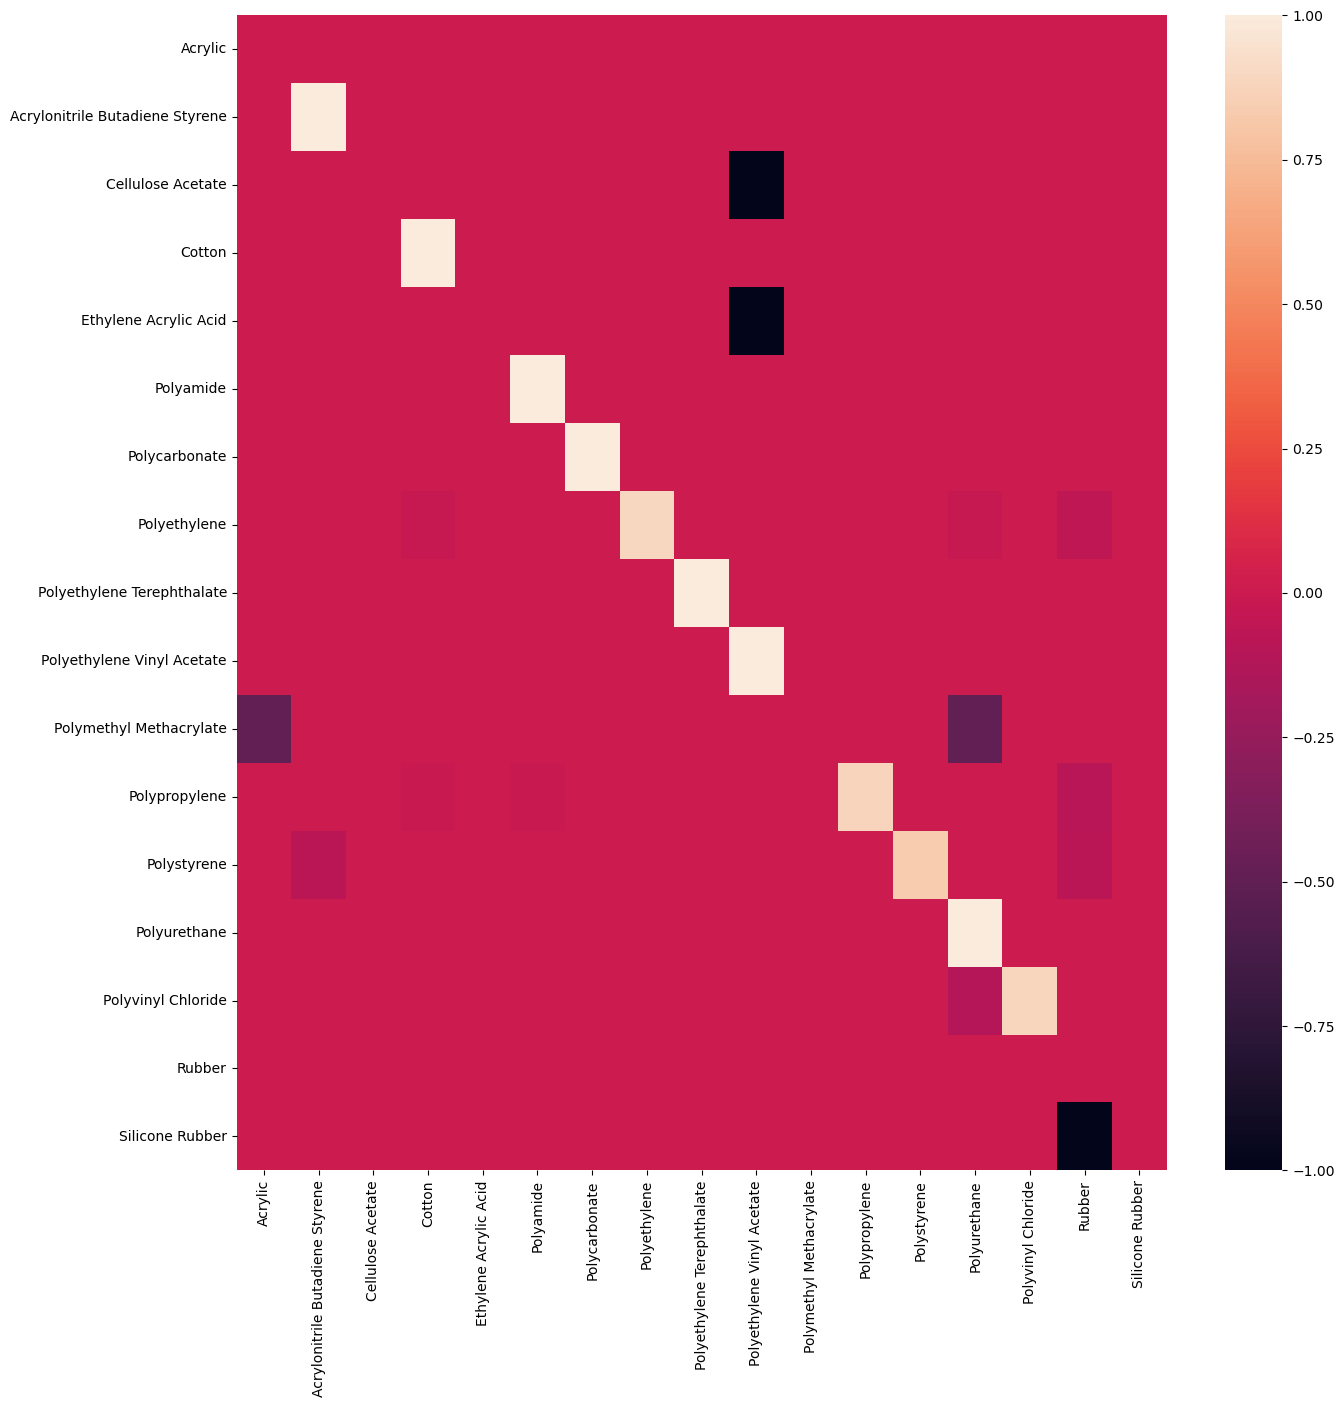

In [21]:
set_classes = set(y_test)
set_classes = set_classes.union(set(y_test_hat))
#set_classes = ['Acrylic', 'Polymethyl Methacrylate']
classes_test_hat = np.array(list(set_classes))
classes_test_hat.sort()

conf_mat = confusion_matrix(y_test, y_test_hat, labels=classes_test_hat)
row_sums = conf_mat.sum(axis=1)
row_sums[row_sums == 0] = 1
conf_mat = conf_mat / row_sums[:, np.newaxis]
conf_mat = 2*np.diag(np.diag(conf_mat)) - conf_mat

conf_mat_df = pd.DataFrame(conf_mat)
conf_mat_df.columns = classes_test_hat
conf_mat_df.index = classes_test_hat


fig, ax = plt.subplots(figsize=(15,15))    
sns.heatmap(conf_mat_df); #, xticklabels=True, yticklabels=True

In [31]:
rf = model_randF(max_depth=10,
                 n_estimators=60)
rf.train_data(x_train, y_train_)
rf.fit()
rf_score = rf.score(X_test, y_test)

In [23]:
#rf.cv(folds, (5, 10, 20, 15, 20, 25, None), np.arange(10, 500, 50), plot_=True)

In [43]:
knn = model_knn(n_neighbors=1)
knn.train_data(x_train, y_train_)
knn.fit()
knn_score = knn.score(X_test, y_test)
#knn.cv(folds, (1, 2, 5, 10), plot_=True)

AttributeError: 'NoneType' object has no attribute 'split'

In [33]:
svm = SVC(gamma='auto', probability=True)
svm.fit(X_train, y_train)
svm_score = svm.score(X_test, y_test)
#svm.score(X_train, y_train)

In [34]:
kernel = 1.0 * RBF(1.0)
gpc = GaussianProcessClassifier(random_state=0).fit(X_train, y_train)
gpc.score(X_train, y_train), gpc.score(X_test, y_test)

(1.0, 0.36923076923076925)

In [41]:
clf_score

0.8871794871794871

In [42]:
pd.DataFrame({'model': ['logistic', 'random forest', 'SVM'],
              'cv_accuracy_flopp':[0.95,0.94,0.97], 
              'accuracy_flopp_e':np.round(np.array([clf_score, rf_score, svm_score]), 2)})

,model,cv_accuracy_flopp,accuracy_flopp_e
0,logistic,0.95,0.89
1,random forest,0.94,0.84
2,SVM,0.97,0.84


In [35]:
pd.DataFrame({'model': ['logistic', 'random forest', 'knn (k=1)', 'SVM'],
              'cv_accuracy_flopp':[0.95,0.94,0.93,0.97], 
              'accuracy_flopp_e':np.round(np.array([clf_score, rf_score, knn_score, svm_score]), 2)})



NameError: name 'knn_score' is not defined

In [82]:
clf = model_logReg(multi_class='ovr', C=1)
clf.train_data(x_train, y_train)
clf.fit()
clf.score(X_test, y_test)

0.9128205128205128

<AxesSubplot: >

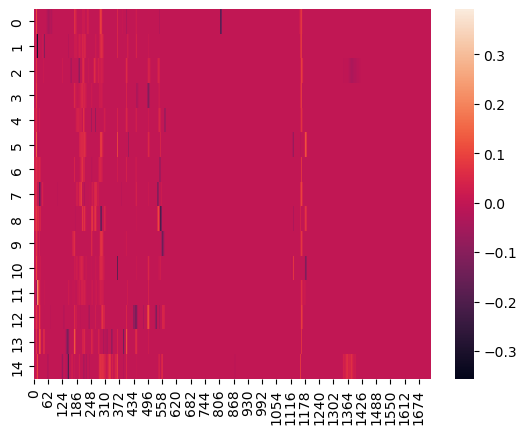

In [83]:
sns.heatmap(clf.model.coef_)

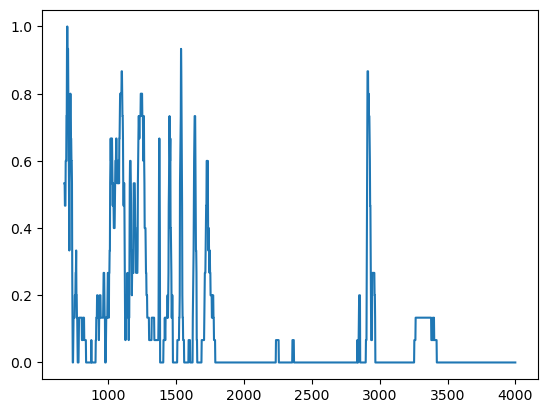

In [103]:
plt.plot(np.array(list(wl_list)), (clf.model.coef_ != 0).mean(0))

In [113]:
clf = model_logReg(C=1)
clf.train_data(x_train, y_train)
clf.fit()
clf.score(X_test, y_test)

0.8974358974358975

In [120]:
clf.model.classes_

array(['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cotton',
       'Polyamide', 'Polycarbonate', 'Polyethylene',
       'Polyethylene Adipate', 'Polyethylene Terephthalate',
       'Polyethylene Vinyl Acetate', 'Polylactic acid', 'Polypropylene',
       'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber'],
      dtype=object)

<AxesSubplot: >

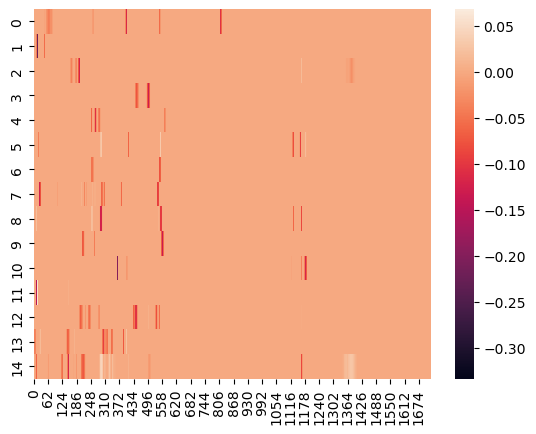

In [108]:
sns.heatmap(clf.model.coef_)

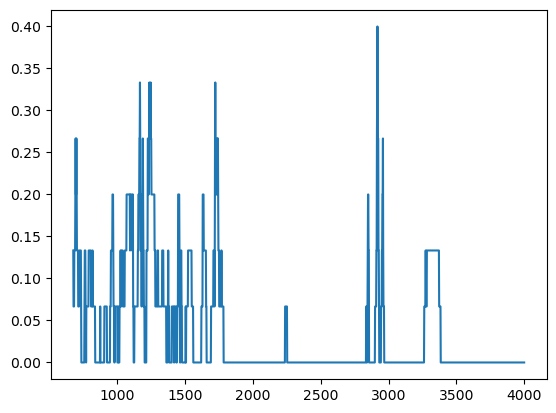

In [109]:
plt.plot(np.array(list(wl_list)), (clf.model.coef_ != 0).mean(0))

In [127]:
((clf.model.coef_ != 0)[5,:]*1).sum()

47

In [134]:
pd.DataFrame([np.array(list(wl_list))[(clf.model.coef_ != 0)[5,:]],clf.model.coef_[5,(clf.model.coef_ != 0)[5,:]]]).T

,0,1
0,713.5627,-0.040259
1,715.4913,-0.108494
2,717.4199,-0.133899
3,719.3484,-0.103072
4,721.2770,-0.041859
5,1232.3420,0.011314
6,1234.2710,0.023396
7,1236.1990,0.031981
8,1238.1280,0.035530
9,1240.0560,0.034463


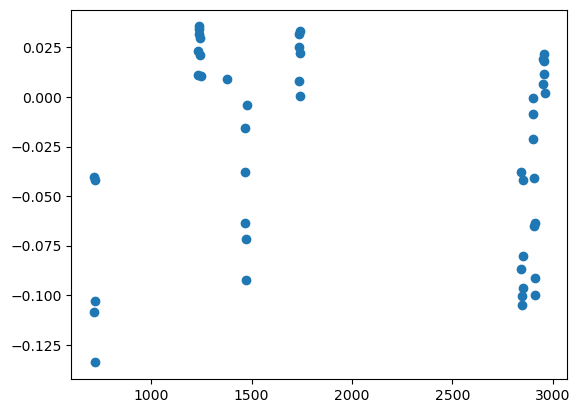

In [131]:
plt.scatter(np.array(list(wl_list))[(clf.model.coef_ != 0)[5,:]],
        clf.model.coef_[5,(clf.model.coef_ != 0)[5,:]])

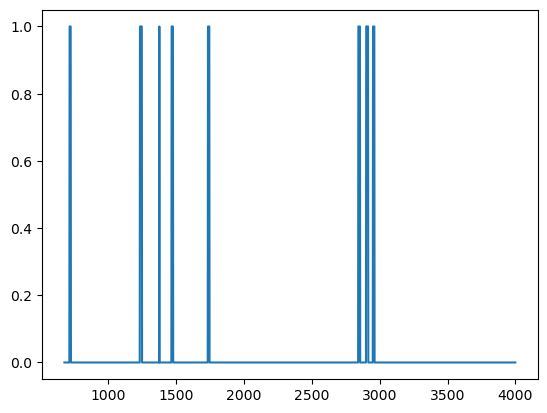

In [126]:
plt.plot(np.array(list(wl_list)), (clf.model.coef_ != 0)[5,:]*1)

In [13]:
df_flopp_pivot.groupby('polymer').count()

,file_name,data_source,wl_67499,wl_67692,wl_67885,wl_68078,wl_68271,wl_68463,wl_68656,wl_68849,...,wl_398245,wl_398438,wl_398631,wl_398824,wl_399017,wl_399209,wl_399402,wl_399595,wl_399788,wl_399981
polymer,,,,,,,,,,,,,,,,,,,,,
Acrylic,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6
Acrylonitrile Butadiene Styrene,15,15,15,15,15,15,15,15,15,15,...,15,15,15,15,15,15,15,15,15,15
Cellulose Acetate,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
Cotton,26,26,26,26,26,26,26,26,26,26,...,26,26,26,26,26,26,26,26,26,26
Ethylene Acrylic Acid,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Nylon,12,12,12,12,12,12,12,12,12,12,...,12,12,12,12,12,12,12,12,12,12
Polyamide,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6
Polycarbonate,9,9,9,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
Polyester,14,14,14,14,14,14,14,14,14,14,...,14,14,14,14,14,14,14,14,14,14


In [14]:
X_train

,wl_67499,wl_67692,wl_67885,wl_68078,wl_68271,wl_68463,wl_68656,wl_68849,wl_69042,wl_69235,...,wl_398245,wl_398438,wl_398631,wl_398824,wl_399017,wl_399209,wl_399402,wl_399595,wl_399788,wl_399981
0,-2.558419,-2.617344,-2.647565,-2.732447,-2.850790,-2.988317,-3.196264,-3.519724,-4.083081,-4.995883,...,0.637547,0.634108,0.648501,0.656325,0.655386,0.664971,0.665558,0.651044,0.645997,0.654486
1,-2.265023,-2.309608,-2.374530,-2.446580,-2.540923,-2.695691,-2.891053,-3.165362,-3.710300,-4.660160,...,0.832796,0.829453,0.840934,0.849702,0.846336,0.842218,0.841419,0.842121,0.844761,0.844858
2,-2.061761,-2.108204,-2.142853,-2.220130,-2.299527,-2.437295,-2.648397,-2.943401,-3.448485,-4.313986,...,0.696705,0.688823,0.696865,0.706376,0.712737,0.715482,0.715432,0.705735,0.699177,0.700378
3,-4.333531,-4.334141,-4.328848,-4.340096,-4.405816,-4.480118,-4.589519,-4.743446,-5.090034,-5.726686,...,0.439976,0.435928,0.447634,0.458499,0.456927,0.451888,0.451876,0.449256,0.447064,0.447839
4,-3.435755,-3.467888,-3.454651,-3.491705,-3.640182,-3.822259,-4.020453,-4.215656,-4.673502,-5.540858,...,0.419135,0.400617,0.409493,0.422987,0.430602,0.433362,0.434856,0.427894,0.423303,0.421881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181,-1.059914,-1.094170,-1.130550,-1.159701,-1.189228,-1.218819,-1.259491,-1.295713,-1.368942,-1.486631,...,0.668248,0.669790,0.673395,0.672920,0.673833,0.675912,0.672733,0.670605,0.673714,0.673574
182,-0.911333,-0.947815,-0.963645,-0.973925,-1.003195,-1.033317,-1.063904,-1.098540,-1.160244,-1.228363,...,0.531372,0.531329,0.529879,0.528860,0.529708,0.530439,0.531653,0.532614,0.533305,0.532427
183,-0.516341,-0.546198,-0.556689,-0.539175,-0.577721,-0.618201,-0.678861,-0.704910,-0.777669,-0.789980,...,0.379056,0.370742,0.381748,0.391027,0.390442,0.384034,0.387614,0.391387,0.387133,0.387726
184,-2.848426,-2.819902,-2.796277,-2.773726,-2.762003,-2.737744,-2.718932,-2.694525,-2.696747,-2.690974,...,0.609851,0.608619,0.608971,0.607739,0.606495,0.605651,0.604783,0.603891,0.603293,0.601322


In [15]:
def corr_matching1(X_ref, y_ref, X_match, r_min=0.5):
    y_ref_ = y_ref.reset_index(drop=True)
    n_ref = X_ref.shape[0]
    #n_match = X_match.shape[0]
    R = np.corrcoef(X_ref, X_match)[:n_ref, n_ref:]
    match_dict = defaultdict(list)
    R_ = np.argsort(-R, 0)
    for i in range(X_match.shape[0]):
        match_dict['hqi'].append(R[R_[:,i],i])
        match_dict['polymer'].append(y_ref_[R_[:,i]].to_numpy())
    return match_dict

In [73]:
n_ref = X_train.shape[0]
np.corrcoef(X_train,  X_test.iloc[idx_cal,:])[:n_ref, n_ref:].shape

(186, 175)

In [242]:
#np.sum([1 - (y in y_train.to_numpy()) for y in (y_test).drop_duplicates()])


In [493]:
idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.2))
idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)

df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_cal,:])[:n_ref, n_ref:])
df_R = 1-df_R
df_R['polymer_ref'] = y_train

quantile_cal = (df_R.
     melt(id_vars=['polymer_ref']).
     groupby(['variable','polymer_ref']).
     max().
     reset_index().
     merge(y_test.iloc[idx_cal].reset_index(drop=True), left_on='variable', right_index=True).
     query('polymer_ref == polymer').groupby('polymer_ref').quantile(.01)).reset_index()#
quantile_cal.columns = ['polymer_ref', 'variable', 'quantile']#[0] = 'polymer'
quantile_cal = quantile_cal.drop(columns=['variable'])

df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_test,:])[:n_ref, n_ref:])
df_R = df_R
df_R['polymer_ref'] = y_train

conf_sets = (df_R.
             melt(id_vars=['polymer_ref']).
             groupby(['variable','polymer_ref']).
             max().
             reset_index().
             merge(quantile_cal, on='polymer_ref').
             merge(y_test.iloc[idx_test].reset_index(drop=True), left_on='variable', right_index=True).
             query('value >= 1-quantile'))

conf_sets.groupby('variable').count().mean()[0]

1.98

In [393]:
conf_sets.groupby('variable').count()

,polymer_ref,value,quantile,polymer
variable,,,,
0,2,2,2,2
2,3,3,3,3
3,3,3,3,3
4,3,3,3,3
5,3,3,3,3
6,4,4,4,4
7,4,4,4,4
8,2,2,2,2
9,3,3,3,3


In [442]:
#idx_test = y_test.reset_index(drop=True).reset_index().iloc[sample(range(y_test.shape[0]),int(y_test.shape[0])),:].drop_duplicates('polymer')['index'].to_numpy()
#idx_cal = np.setdiff1d(list(range(y_test.shape[0])), idx_test)
cov = np.zeros(100)
adj_cov = np.zeros(100)
set_size = np.zeros(100)
for j in range(100):
    idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.9))
    idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)

    df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_cal,:])[:n_ref, n_ref:])
    df_R = 1-df_R
    df_R['polymer_ref'] = y_train

    quantile_cal = (df_R.
     melt(id_vars=['polymer_ref']).
     groupby(['variable','polymer_ref']).
     max().
     reset_index().
     merge(y_test.iloc[idx_cal].reset_index(drop=True), left_on='variable', right_index=True).
     query('polymer_ref == polymer').groupby('polymer_ref').quantile(1)).reset_index()#
    quantile_cal.columns = ['polymer_ref', 'variable', 'quantile']#[0] = 'polymer'
    quantile_cal = quantile_cal.drop(columns=['variable'])

    df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_test,:])[:n_ref, n_ref:])
    df_R = df_R
    df_R['polymer_ref'] = y_train

    conf_sets = (df_R.
     melt(id_vars=['polymer_ref']).
     groupby(['variable','polymer_ref']).
     max().
     reset_index().
     merge(quantile_cal, on='polymer_ref').
     merge(y_test.iloc[idx_test].reset_index(drop=True), left_on='variable', right_index=True).
     query('value >= 1-quantile'))
     #query('polymer == polymer_ref'))#.
     #query('polymer_ref == polymer').groupby('polymer_ref').quantile(.9))#

    coverage = 1*np.array([y_test.iloc[idx_test].reset_index(drop=True)[i] in list(conf_sets.query('variable == @i')['polymer_ref']) for i in range(len(idx_test))])
    true_coverage = 1*np.array([y_test.iloc[idx_test].reset_index(drop=True)[i] in y_train.to_numpy() for i in range(len(idx_test))])

    cov[j] = coverage.mean()
    adj_cov[j] = ((coverage.sum())/true_coverage.sum())
    set_size[j] = conf_sets.groupby('variable').count().mean()[0]


In [494]:
#idx_test = y_test.reset_index(drop=True).reset_index().iloc[sample(range(y_test.shape[0]),int(y_test.shape[0])),:].drop_duplicates('polymer')['index'].to_numpy()
#idx_cal = np.setdiff1d(list(range(y_test.shape[0])), idx_test)
res_dict = defaultdict(list)

for alpha in np.linspace(0,1,20):
    cov = np.zeros(100)
    adj_cov = np.zeros(100)
    set_size = np.zeros(100)
    acc = np.zeros(100)
    for j in range(100):
        idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.1))
        idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)

        df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_cal,:])[:n_ref, n_ref:])
        df_R = 1-df_R
        df_R['polymer_ref'] = y_train

        quantile_cal = (df_R.
         melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().
         merge(y_test.iloc[idx_cal].reset_index(drop=True), left_on='variable', right_index=True).
         query('polymer_ref == polymer').groupby('polymer_ref').quantile(alpha)).reset_index()#
        quantile_cal.columns = ['polymer_ref', 'variable', 'quantile']#[0] = 'polymer'
        quantile_cal = quantile_cal.drop(columns=['variable'])

        df_R = pd.DataFrame(np.corrcoef(X_train,  X_test.iloc[idx_test,:])[:n_ref, n_ref:])
        df_R = df_R
        df_R['polymer_ref'] = y_train

        conf_sets = (df_R.
         melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().
         merge(quantile_cal, on='polymer_ref').
         merge(y_test.iloc[idx_test].reset_index(drop=True), left_on='variable', right_index=True).
         query('value >= 1-quantile'))
         #query('polymer == polymer_ref'))#.
         #query('polymer_ref == polymer').groupby('polymer_ref').quantile(.9))#

        coverage = 1*np.array([y_test.iloc[idx_test].reset_index(drop=True)[i] in list(conf_sets.query('variable == @i')['polymer_ref']) for i in range(len(idx_test))])
        true_coverage = 1*np.array([y_test.iloc[idx_test].reset_index(drop=True)[i] in y_train.to_numpy() for i in range(len(idx_test))])

        cov[j] = coverage.mean()
        adj_cov[j] = ((coverage.sum())/true_coverage.sum())
        set_size[j] = conf_sets.groupby('variable').count().mean()[0]
        acc[j] = (corr_matching(X_train, y_train, X_test.iloc[idx_test,:], r_min=0.75)[0].reset_index(drop=True) == y_test.iloc[idx_test].reset_index(drop=True)).mean()
        
    res_dict['alpha'].append(alpha)
    res_dict['cov_mean'].append(cov.mean())
    res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict['set_size_mean'].append(set_size.mean())
    res_dict['acc_mean'].append(acc.mean())
    
    res_dict['cov_sd'].append(cov.std())
    res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict['set_size_sd'].append(set_size.std())
    res_dict['acc_sd'].append(acc.std())
    

In [495]:
res_df = pd.DataFrame(res_dict)

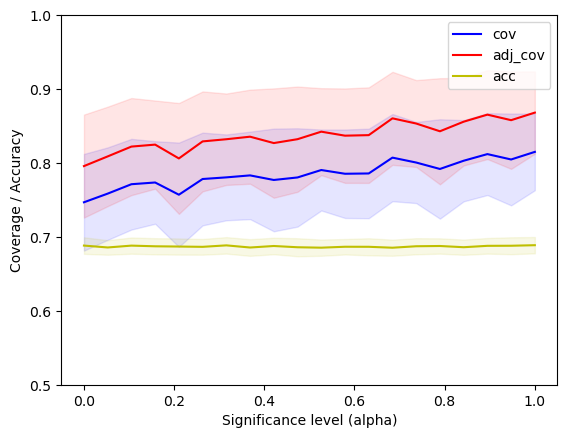

In [496]:
res_df = pd.DataFrame(res_dict)
_ = plt.plot(res_df['alpha'], res_df['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df['alpha'], (res_df['cov_mean']-res_df['cov_sd']), (res_df['cov_mean']+res_df['cov_sd']), color = 'b', alpha=.1)

_ = plt.plot(res_df['alpha'], res_df['adj_cov_mean'], label='adj_cov', c='r')
_ = plt.fill_between(res_df['alpha'], (res_df['adj_cov_mean']-res_df['adj_cov_sd']), (res_df['adj_cov_mean']+res_df['adj_cov_sd']), color = 'r', alpha=.1)

_ = plt.plot(res_df['alpha'], res_df['acc_mean'], label='acc', c = 'y')
_ = plt.fill_between(res_df['alpha'], (res_df['acc_mean']-res_df['acc_sd']), (res_df['acc_mean']+res_df['acc_sd']), color = 'y', alpha=.1)

_ = plt.legend()
_ = plt.xlabel('Significance level (alpha)')
_ = plt.ylabel('Coverage / Accuracy')
_ = plt.ylim((.5,1))

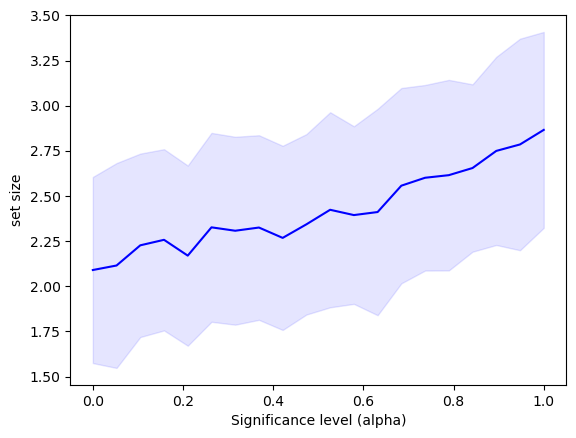

In [497]:

_ = plt.plot(res_df['alpha'], res_df['set_size_mean'], c='b')
_ = plt.fill_between(res_df['alpha'], (res_df['set_size_mean']-res_df['set_size_sd']), (res_df['set_size_mean']+res_df['set_size_sd']), color = 'b', alpha=.1)
_ = plt.xlabel('Significance level (alpha)')
_ = plt.ylabel('set size')

(2.6248515221878224,
 (array([ 4.,  3.,  5., 23., 18., 18., 11.,  8.,  8.,  2.]),
  array([2.05 , 2.165, 2.28 , 2.395, 2.51 , 2.625, 2.74 , 2.855, 2.97 ,
         3.085, 3.2  ]),
  <BarContainer object of 10 artists>))

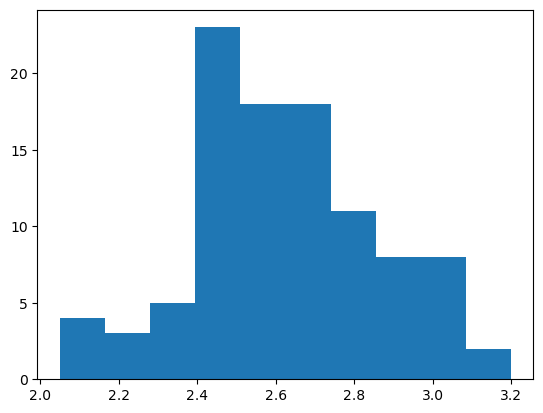

In [439]:
set_size.mean(), plt.hist(set_size)


(0.835,
 (array([ 2.,  4., 13.,  0., 28., 23.,  0., 17., 12.,  1.]),
  array([0.65 , 0.685, 0.72 , 0.755, 0.79 , 0.825, 0.86 , 0.895, 0.93 ,
         0.965, 1.   ]),
  <BarContainer object of 10 artists>))

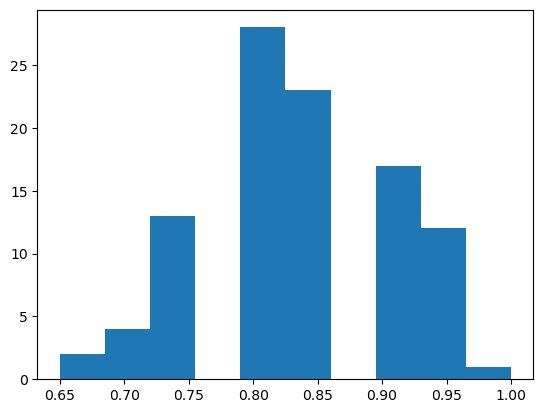

In [440]:

cov.mean(), plt.hist(cov)


(0.8871490798073616,
 (array([ 2.,  2.,  9.,  1., 27.,  1., 24.,  4., 20., 10.]),
  array([0.72222222, 0.75      , 0.77777778, 0.80555556, 0.83333333,
         0.86111111, 0.88888889, 0.91666667, 0.94444444, 0.97222222,
         1.        ]),
  <BarContainer object of 10 artists>))

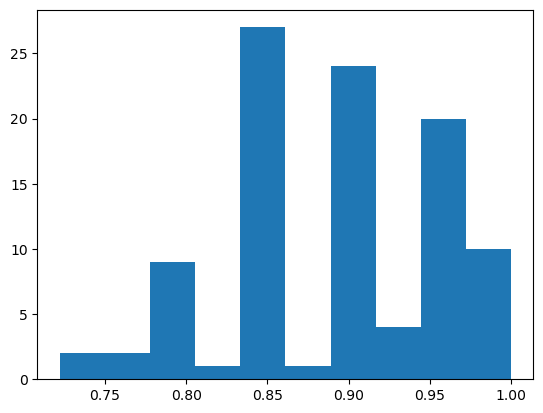

In [441]:
adj_cov.mean(), plt.hist(adj_cov)

In [479]:
cov = np.zeros(100)
adj_cov = np.zeros(100)
for j in range(100):
    idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.9))
    idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)
    cov[j] = (corr_matching(X_train, y_train, X_test.iloc[idx_test,:], r_min=0.95)[0].reset_index(drop=True) == y_test.iloc[idx_test].reset_index(drop=True)).mean()



In [480]:
cov.mean(), cov.std()


(0.6895, 0.09035900619196738)

In [297]:
for i in range(len(idx_test)):
    p = y_test.iloc[idx_test].reset_index(drop=True)[i]
    print(p in list(conf_sets.query('variable == @i')['polymer_ref']), 
          p in y_train.to_numpy())

True True
True True
True True
False True
True True
True True
True True
False True
True True
True True


In [14]:
(df_R.
 melt(id_vars=['polymer_ref']).
 groupby(['variable','polymer_ref']).
 max().
 reset_index().
 merge(quantile_cal, on='polymer_ref').
 merge(y_test.iloc[idx_test].reset_index(drop=True), left_on='variable', right_index=True).
 query('variable == 6'))

NameError: name 'df_R' is not defined

In [17]:
idx_test = y_test.reset_index(drop=True).reset_index().iloc[sample(range(y_test.shape[0]),int(y_test.shape[0])),:].drop_duplicates('polymer')['index'].to_numpy()



In [18]:
y_test[idx_test]

40                        Polyethylene
164                      Polypropylene
5                               Cotton
82          Polyethylene Terephthalate
177                        Polystyrene
189                 Polyvinyl Chloride
17          Polyethylene Vinyl Acetate
183                       Polyurethane
14                   Cellulose Acetate
25                           Polyamide
194                    Silicone Rubber
27                       Polycarbonate
100            Polymethyl Methacrylate
0      Acrylonitrile Butadiene Styrene
15               Ethylene Acrylic Acid
Name: polymer, dtype: object

In [19]:
df_test = df_cal.merge(pd.DataFrame({'polymer':dict_test['polymer'][k],'hqi':dict_test['hqi'][k]}).groupby('polymer').max().reset_index(),
                     on='polymer',
                     how='left') 
df_test['comp'] = df_test['hqi_x'] <= df_test['hqi_y']
#df_test_list.append(
(df_test.groupby('polymer').
         mean().
         reset_index().
         sort_values(['comp', 'hqi_y'], ascending=False).
         iloc[:,[0,2,3]].
         reset_index(drop=True))


NameError: name 'df_cal' is not defined

In [27]:
match_dict = corr_matching1(X_train, y_train, X_test.iloc[idx_cal,:], r_min=0.8) 
class_match, hqi = corr_matching(X_train, y_train, X_test.iloc[idx_cal,:], r_min=0.8) 

48                        Polyethylene
7                               Cotton
121                      Polypropylene
187                 Polyvinyl Chloride
77          Polyethylene Terephthalate
175                        Polystyrene
21                           Polyamide
100            Polymethyl Methacrylate
13                   Cellulose Acetate
15               Ethylene Acrylic Acid
194                    Silicone Rubber
20          Polyethylene Vinyl Acetate
182                       Polyurethane
27                       Polycarbonate
0      Acrylonitrile Butadiene Styrene
Name: polymer, dtype: object

In [21]:
idx_test = y_test.reset_index(drop=True).reset_index().iloc[sample(range(y_test.shape[0]),int(y_test.shape[0])),:].drop_duplicates('polymer')['index'].to_numpy()
idx_cal = np.setdiff1d(list(range(y_test.shape[0])), idx_test)
#idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.95))
#idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)

class_match, hqi = corr_matching(X_train, y_train, X_test.iloc[idx_cal,:], r_min=0.8) 
df_cal = pd.DataFrame({'polymer':class_match.to_numpy(), 'hqi':hqi})

dict_test = corr_matching1(X_train, y_train, X_test.iloc[idx_test,:], r_min=0.8)

df_test_list = []
for k in range(len(idx_test)):
    df_test = df_cal.merge(pd.DataFrame({'polymer':dict_test['polymer'][k],'hqi':dict_test['hqi'][k]}).groupby('polymer').max().reset_index(),
                     on='polymer',
                     how='left') 
    df_test['comf'] = df_test['hqi_x'] <= df_test['hqi_y']
    df_test_conf = (df_test.groupby('polymer').
         mean().
         reset_index().
         sort_values('comf', ascending=False).
         iloc[:,[0,2,3]].
         reset_index(drop=True))
    df_test_conf['index'] = k
    df_test_list.append(df_test_conf)

df_test = pd.concat(df_test_list).reset_index(drop=True)
df_test = df_test.merge(y_test[idx_test].reset_index(drop=True).reset_index(), on='index', how='outer')#.sort_values('comp', ascending=False)
df_test['acc'] = (df_test['polymer_x'] == df_test['polymer_y'])*1
df_test.query('comf > 0').groupby('index').max('acc').mean()['acc']
#
#(df_test['polymer'] == y_test.iloc[idx_test].reset_index(drop=True)).mean()


0.5

In [22]:
acc_conformal = np.zeros(100)
for j in trange(100):
    idx_cal = sample(range(y_test.shape[0]),int(y_test.shape[0]*.9))
    idx_test = np.setdiff1d(list(range(y_test.shape[0])), idx_cal)

    class_match, hqi = corr_matching(X_train, y_train, X_test.iloc[idx_cal,:],r_min=0.8) 
    df_cal = pd.DataFrame({'polymer':class_match.to_numpy(), 'hqi':hqi})

    dict_test = corr_matching1(X_train, y_train, X_test.iloc[idx_test,:],r_min=0.8)

    df_test_list = []
    for k in range(len(idx_test)):
        df_test = df_cal.merge(pd.DataFrame({'polymer':dict_test['polymer'][k],'hqi':dict_test['hqi'][k]}).groupby('polymer').max().reset_index(),
                     on='polymer',
                     how='left') 
        df_test['comf'] = df_test['hqi_x'] <= df_test['hqi_y']
        df_test_conf = (df_test.groupby('polymer').
         mean().
         reset_index().
         sort_values('comf', ascending=False).
         iloc[:,[0,2,3]].
         reset_index(drop=True))
        df_test_conf['index'] = k
        df_test_list.append(df_test_conf)

    df_test = pd.concat(df_test_list).reset_index(drop=True)
    df_test = df_test.merge(y_test[idx_test].reset_index(drop=True).reset_index(), on='index', how='outer')#.sort_values('comp', ascending=False)
    df_test['acc'] = (df_test['polymer_x'] == df_test['polymer_y'])*1
    acc_conformal[j] = df_test.query('comf > 0').groupby('index').max('acc').mean()['acc']

    #df_test = pd.concat(df_test_list).reset_index(drop=True)
    #acc_conformal[j] = (df_test['polymer'] == y_test.iloc[idx_test].reset_index(drop=True)).mean()



100%|█████████████████████████████████████████| 100/100 [00:07<00:00, 12.54it/s]


(0.7961146800825594,
 (array([ 8.,  9.,  8.,  5., 17., 14., 26.,  1.,  7.,  5.]),
  array([0.65, 0.68, 0.71, 0.74, 0.77, 0.8 , 0.83, 0.86, 0.89, 0.92, 0.95]),
  <BarContainer object of 10 artists>))

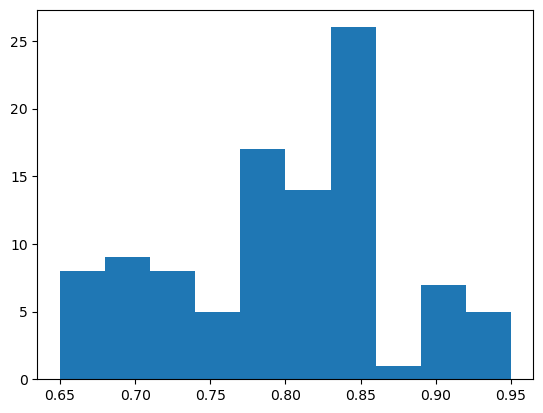

In [23]:
acc_conformal.mean(), plt.hist(acc_conformal)

In [351]:
#p_val = df_cal.groupby('polymer').quantile(.9).reset_index()

,polymer,hqi
0,Acrylic,0.869148
1,Acrylonitrile Butadiene Styrene,0.975896
2,Cotton,0.990062
3,Polyamide,0.990778
4,Polycarbonate,0.980350
5,Polyethylene,0.994193
6,Polyethylene Terephthalate,0.996535
7,Polyethylene Vinyl Acetate,0.931583
8,Polypropylene,0.990559
9,Polystyrene,0.987040


In [357]:
k=4
p_val = df_cal.groupby('polymer').quantile(.9).reset_index()
(pd.DataFrame({'polymer':dict_test['polymer'][k],'hqi':dict_test['hqi'][k]}).
 merge(p_val, on='polymer').
 query('hqi_x>=hqi_y'))#.loc[:,['polymer','hqi_x']])

,polymer,hqi_x,hqi_y
18,Polyethylene Vinyl Acetate,0.943081,0.931583


In [162]:
class_match, hqi = corr_matching(X_train, y_train, X_test.iloc[idx_test,:],r_min=0.5) 
pd.DataFrame([class_match.to_numpy(),hqi]).T

,0,1
0,Cotton,0.986503
1,Cotton,0.992942
2,Polyethylene Vinyl Acetate,0.904408
3,Polyamide,0.987212
4,Polyethylene,0.975371
5,Polyethylene,0.988271
6,Polyethylene Terephthalate,0.997586
7,Polyethylene Terephthalate,0.996393
8,Polyethylene Terephthalate,0.989687
9,Polypropylene,0.966914


In [ ]:
quantile_cal = (df_R.
         melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().
         merge(y_test.iloc[idx_cal].reset_index(drop=True), left_on='variable', right_index=True).
         query('polymer_ref == polymer').groupby('polymer_ref').quantile(alpha)).reset_index()#
quantile_cal.columns = ['polymer_ref', 'variable', 'quantile']#[0] = 'polymer'
quantile_cal = quantile_cal.drop(columns=['variable'])

In [16]:
n_ref=X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
(df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().query('variable==0'))
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx = (smx / smx.sum(1)[:,None])
pd.DataFrame(smx)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.017309,0.536919,0.008794,0.005978,0.000868,0.003190,0.004962,0.001006,0.004920,0.008122,0.001187,0.005471,0.342465,0.011212,0.019262,0.028334
1,0.028320,0.029987,0.513917,0.003718,0.002537,0.014145,0.008463,0.001867,0.010969,0.007014,0.011826,0.001422,0.007894,0.068831,0.146066,0.143022
2,0.012271,0.016869,0.659885,0.001756,0.001344,0.008361,0.008349,0.001276,0.007228,0.004642,0.008410,0.001132,0.004491,0.041605,0.110541,0.111842
3,0.022152,0.022815,0.534563,0.002002,0.002360,0.014500,0.009028,0.002744,0.010935,0.007955,0.012799,0.001402,0.004551,0.059198,0.145607,0.147390
4,0.021110,0.030782,0.506737,0.002156,0.001947,0.013699,0.010823,0.001836,0.011087,0.008303,0.010749,0.001282,0.005729,0.060508,0.151215,0.162036
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,0.072875,0.069337,0.023085,0.014005,0.005689,0.038283,0.021449,0.009843,0.161579,0.039547,0.006089,0.032259,0.084792,0.063120,0.290338,0.067710
191,0.078178,0.036001,0.059239,0.004514,0.014002,0.114979,0.011523,0.063081,0.092979,0.073953,0.035400,0.007135,0.008642,0.118442,0.190316,0.091617
192,0.078487,0.087267,0.110847,0.009481,0.006265,0.060759,0.009484,0.004823,0.051514,0.036029,0.011543,0.003187,0.018594,0.099443,0.290402,0.121874
193,0.089457,0.082996,0.056779,0.019392,0.007767,0.057590,0.014868,0.009016,0.092528,0.042356,0.010581,0.012217,0.043122,0.113090,0.265211,0.083030


In [17]:
(df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().query('variable==0'))

,variable,polymer_ref,value
0,0,Acrylic,594.223527
1,0,Acrylonitrile Butadiene Styrene,18432.859936
2,0,Cotton,301.914087
3,0,Nylon,205.233687
4,0,Polycarbonate,29.793867
5,0,Polyester,109.524431
6,0,Polyethylene,170.345644
7,0,Polyethylene Adipate,34.546415
8,0,Polyethylene Terephthalate,168.906315
9,0,Polyethylene Vinyl Acetate,278.833650


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.485513,0.965005,0.424021,0.392519,0.266831,0.346189,0.378161,0.274847,0.377520,0.417330,0.284072,0.385624,0.882005,0.445129,0.496007,0.535807
1,0.543428,0.549680,0.970289,0.362068,0.335422,0.472981,0.426806,0.315460,0.449529,0.411065,0.456339,0.298756,0.420905,0.649052,0.754453,0.751282
2,0.442308,0.471375,0.981396,0.299821,0.284200,0.409638,0.409519,0.281284,0.397882,0.364161,0.410115,0.274600,0.361758,0.564651,0.686523,0.688131
3,0.514946,0.517988,0.973368,0.318386,0.329049,0.473099,0.430325,0.339112,0.447140,0.419566,0.461437,0.296484,0.375232,0.626814,0.750436,0.752265
4,0.521866,0.562754,0.985410,0.330674,0.323999,0.478625,0.456590,0.320223,0.458804,0.433015,0.455971,0.298032,0.402052,0.644203,0.773712,0.784482
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,0.624633,0.618448,0.496336,0.449123,0.375078,0.549175,0.489092,0.418537,0.732464,0.552755,0.380206,0.530689,0.643844,0.606936,0.823551,0.615517
191,0.722949,0.619088,0.683931,0.408694,0.512543,0.780934,0.492953,0.692579,0.748459,0.714959,0.617007,0.447883,0.465386,0.785582,0.863745,0.746252
192,0.683709,0.698363,0.732582,0.448008,0.412385,0.649582,0.448035,0.391366,0.628488,0.585115,0.465986,0.360231,0.512612,0.716848,0.888202,0.746611
193,0.728345,0.717506,0.665046,0.536463,0.446753,0.666937,0.508706,0.460280,0.733279,0.627189,0.475247,0.489111,0.629440,0.763308,0.905176,0.717566


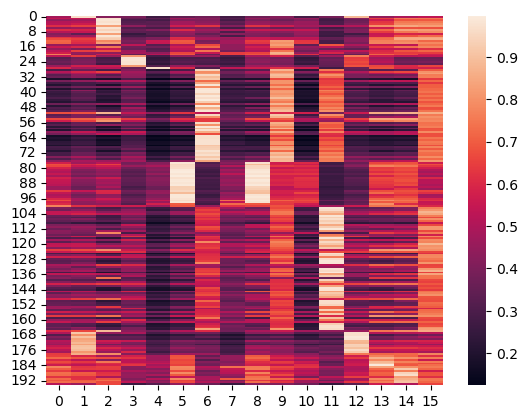

In [18]:
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
df_R = pd.DataFrame(np.exp(-2*(1 - df_R)))
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
sns.heatmap(pd.DataFrame(smx))
pd.DataFrame(smx)

<AxesSubplot: >

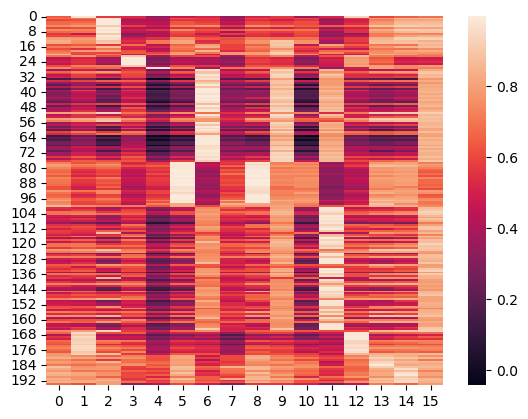

In [19]:
df_R = pd.DataFrame(np.corrcoef(X_train,  X_test)[:n_ref, n_ref:])
#df_R = pd.DataFrame(np.exp(-2*(1 - df_R)))
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
sns.heatmap(pd.DataFrame(smx))

In [20]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
df_R = 1-df_R
df_R = np.exp(df_R/.2)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = 1-smx
smx = (smx / smx.sum(1)[:,None])

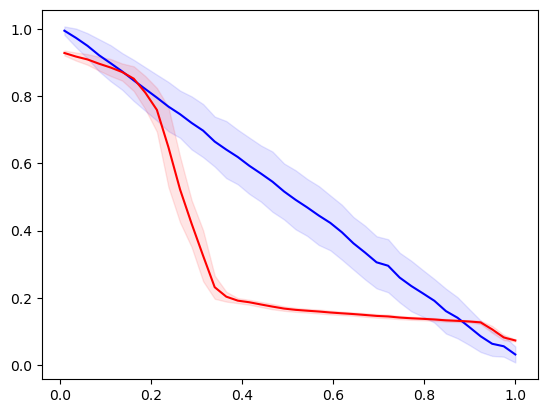

In [44]:
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx = (smx / smx.sum(1)[:,None])
smx = 1-smx
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()


res_dict = defaultdict(list)    

for alpha in np.linspace(0.01,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        # Problem setup
        n=150 # number of calibration points
        #alpha = alpha # 1-alpha is the desired coverage
        # Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
        lam_reg = 2
        k_reg = 2
        disallow_zero_sets = True # Set this to False in order to see the coverage upper bound hold
        rand = True # Set this to True in order to see the coverage upper bound hold
        reg_vec = np.array(k_reg*[0,] + (smx.shape[1]-k_reg)*[lam_reg,])[None,:]


        # Split the softmax scores into calibration and validation sets (save the shuffling)
        idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
        cal_pi = cal_smx.argsort(1)[:,::-1]; 
        cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
        cal_srt_reg = cal_srt + reg_vec
        cal_L = np.where(cal_pi == cal_labels[:,None])[1]

        cal_scores = cal_srt_reg[np.arange(n),cal_L]
        #cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
        # Get the score quantile
        qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
        # Deploy
        n_val = val_smx.shape[0]
        val_pi = val_smx.argsort(1)[:,::-1]
        val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
        val_srt_reg = val_srt + reg_vec
        val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
        #indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
        indicators = val_srt_reg <= qhat
        if disallow_zero_sets: indicators[:,0] = True
        prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)


        # Calculate empirical coverage
        empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()
        #print(f"The empirical coverage is: {empirical_coverage}")
        #print(f"The quantile is: {qhat}")

        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
    res_dict['alpha'].append(alpha)    
    res_dict['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df = pd.DataFrame(res_dict)
_ = plt.plot(res_df['alpha'], res_df['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df['alpha'], (res_df['cov_mean']-res_df['cov_sd']), (res_df['cov_mean']+res_df['cov_sd']), color = 'b', alpha=.1)
#_ = plt.plot(res_df['alpha'], res_df['adj_cov_mean'], label='adj_cov', c='r')
#_ = plt.fill_between(res_df['alpha'], (res_df['adj_cov_mean']-res_df['adj_cov_sd']), (res_df['adj_cov_mean']+res_df['adj_cov_sd']), color = 'r', alpha=.1)

#_ = plt.legend()
#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('Coverage / Accuracy')
#_ = plt.ylim((.5,1))

_ = plt.plot(res_df['alpha'], res_df['set_size_mean']/16, c='r')
_ = plt.fill_between(res_df['alpha'], (res_df['set_size_mean']-res_df['set_size_sd'])/16, (res_df['set_size_mean']+res_df['set_size_sd'])/16, color = 'r', alpha=.1)

#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('set size')

In [51]:
reg_vec

array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
        0.01, 0.01, 0.01, 0.01]])

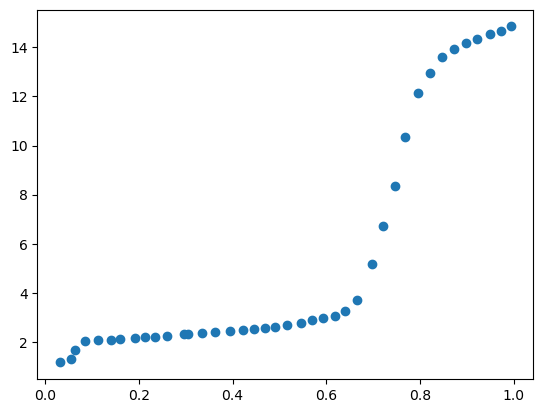

In [45]:
plt.scatter(res_df['cov_mean'], res_df['set_size_mean'])

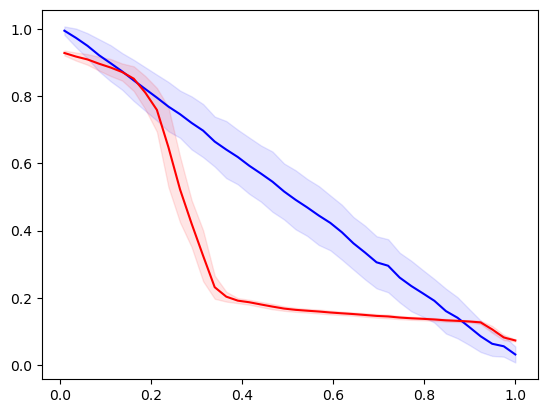

In [46]:
_ = plt.plot(res_df['alpha'], res_df['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df['alpha'], (res_df['cov_mean']-res_df['cov_sd']), (res_df['cov_mean']+res_df['cov_sd']), color = 'b', alpha=.1)
#_ = plt.plot(res_df['alpha'], res_df['adj_cov_mean'], label='adj_cov', c='r')
#_ = plt.fill_between(res_df['alpha'], (res_df['adj_cov_mean']-res_df['adj_cov_sd']), (res_df['adj_cov_mean']+res_df['adj_cov_sd']), color = 'r', alpha=.1)

#_ = plt.legend()
#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('Coverage / Accuracy')
#_ = plt.ylim((.5,1))

_ = plt.plot(res_df['alpha'], res_df['set_size_mean']/16, c='r')
_ = plt.fill_between(res_df['alpha'], (res_df['set_size_mean']-res_df['set_size_sd'])/16, (res_df['set_size_mean']+res_df['set_size_sd'])/16, color = 'r', alpha=.1)


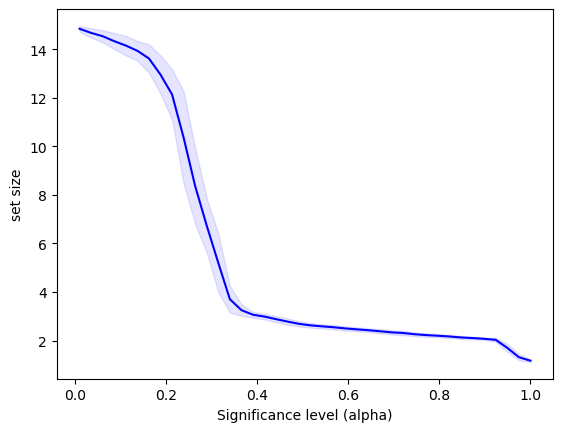

In [47]:

_ = plt.plot(res_df['alpha'], res_df['set_size_mean'], c='b')
_ = plt.fill_between(res_df['alpha'], (res_df['set_size_mean']-res_df['set_size_sd']), (res_df['set_size_mean']+res_df['set_size_sd']), color = 'b', alpha=.1)

_ = plt.xlabel('Significance level (alpha)')
_ = plt.ylabel('set size')

In [48]:
1-clf.model.predict_proba(X_test)

array([[0.9999861 , 0.00177427, 0.99999876, ..., 0.99999987, 0.99999476,
        0.99984378],
       [0.99984135, 0.99899885, 0.00638315, ..., 0.99801113, 0.99834654,
        0.99959237],
       [0.99996727, 0.99979768, 0.00212811, ..., 0.99956881, 0.99911011,
        0.99984272],
       ...,
       [0.99991216, 0.99895304, 0.99797003, ..., 0.99929425, 0.01033841,
        0.99737243],
       [0.99852822, 0.99758047, 0.99894289, ..., 0.99932708, 0.02424087,
        0.99662775],
       [0.96617793, 0.99393673, 0.63419109, ..., 0.97301775, 0.99882808,
        0.44534222]])

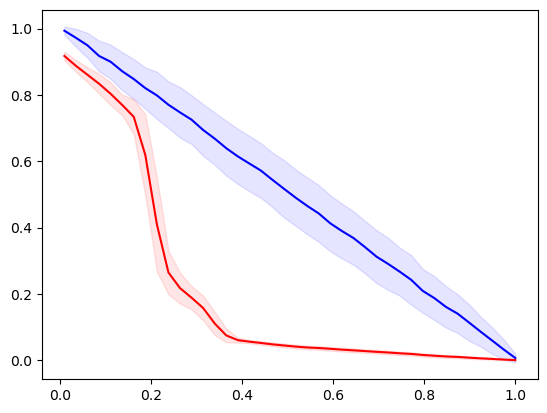

In [49]:
#df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
#df_R = 1-df_R
#df_R = np.exp(df_R/.1)
#df_R = pd.DataFrame(df_R)
#df_R['polymer_ref'] = y_train
#smx = (df_R.melt(id_vars=['polymer_ref']).
#         groupby(['variable','polymer_ref']).
#         max().
#         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = (smx / smx.sum(1)[:,None])
#smx = 1-smx

smx = 1-clf.model.predict_proba(X_test)
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()


res_dict = defaultdict(list)    

for alpha in np.linspace(0.01,1, 40):
    #print(alpha)
    cov = np.zeros(1000)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(1000)

    for i in range(1000):
        # Problem setup
        n=150 # number of calibration points
        #alpha = alpha # 1-alpha is the desired coverage
        # Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
        lam_reg = 0.01
        k_reg = 5
        disallow_zero_sets = False # Set this to False in order to see the coverage upper bound hold
        rand = True # Set this to True in order to see the coverage upper bound hold
        reg_vec = np.array(k_reg*[0,] + (smx.shape[1]-k_reg)*[lam_reg,])[None,:]


        # Split the softmax scores into calibration and validation sets (save the shuffling)
        idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
        cal_pi = cal_smx.argsort(1)[:,::-1]; 
        cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
        cal_srt_reg = cal_srt + reg_vec
        cal_L = np.where(cal_pi == cal_labels[:,None])[1]

        cal_scores = cal_srt_reg[np.arange(n),cal_L]
        #cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
        # Get the score quantile
        qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
        # Deploy
        n_val = val_smx.shape[0]
        val_pi = val_smx.argsort(1)[:,::-1]
        val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
        val_srt_reg = val_srt + reg_vec
        val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
        #indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
        indicators = val_srt_reg <= qhat
        if disallow_zero_sets: indicators[:,0] = True
        prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)


        # Calculate empirical coverage
        empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()
        #print(f"The empirical coverage is: {empirical_coverage}")
        #print(f"The quantile is: {qhat}")

        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
    res_dict['alpha'].append(alpha)    
    res_dict['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df_log = pd.DataFrame(res_dict)
_ = plt.plot(res_df_log['alpha'], res_df_log['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['cov_mean']-res_df_log['cov_sd']), (res_df_log['cov_mean']+res_df_log['cov_sd']), color = 'b', alpha=.1)
#_ = plt.plot(res_df['alpha'], res_df['adj_cov_mean'], label='adj_cov', c='r')
#_ = plt.fill_between(res_df['alpha'], (res_df['adj_cov_mean']-res_df['adj_cov_sd']), (res_df['adj_cov_mean']+res_df['adj_cov_sd']), color = 'r', alpha=.1)

#_ = plt.legend()
#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('Coverage / Accuracy')
#_ = plt.ylim((.5,1))

_ = plt.plot(res_df_log['alpha'], res_df_log['set_size_mean']/16, c='r')
_ = plt.fill_between(res_df_log['alpha'], (res_df_log['set_size_mean']-res_df_log['set_size_sd'])/16, (res_df_log['set_size_mean']+res_df_log['set_size_sd'])/16, color = 'r', alpha=.1)

#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('set size')

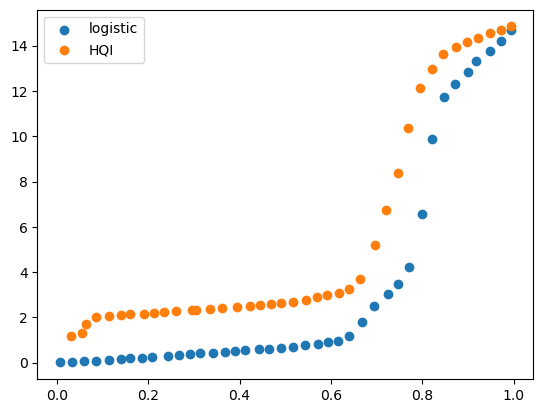

In [50]:
plt.scatter(res_df_log['cov_mean'], res_df_log['set_size_mean'], label='logistic')
plt.scatter(res_df['cov_mean'], res_df['set_size_mean'], label='HQI')
plt.legend()

high HQI vs size


In [126]:
n = X_train.shape[0] // 3
idx_train = np.array([1] * n + [0] * (X_train.shape[0]-n)) > 0
np.random.shuffle(idx_train)

(62, 1725)

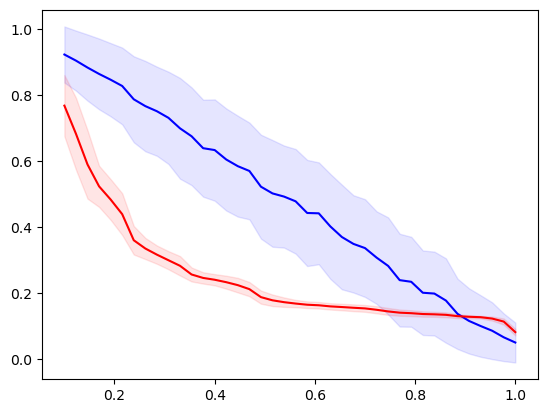

In [130]:
X_train_1, X_test_1 = X_train[~idx_train].reset_index(drop=True), X_train[idx_train].reset_index(drop=True)
y_train_1, y_test_1 = y_train[~idx_train].reset_index(drop=True), y_train[idx_train].reset_index(drop=True)

n_ref = X_train_1.shape[0]
df_R = np.corrcoef(X_train_1,  X_test_1)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train_1
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx = (smx / smx.sum(1)[:,None])
smx = 1-smx
labels = y_test_1.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())}))['id'].to_numpy()


res_dict = defaultdict(list)    

for alpha in np.linspace(0.1,1, 40):
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)

    for i in range(500):
        # Problem setup
        n=50 # number of calibration points
        #alpha = alpha # 1-alpha is the desired coverage
        # Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
        lam_reg = 2
        k_reg = 2
        disallow_zero_sets = True # Set this to False in order to see the coverage upper bound hold
        rand = True # Set this to True in order to see the coverage upper bound hold
        reg_vec = np.array(k_reg*[0,] + (smx.shape[1]-k_reg)*[lam_reg,])[None,:]


        # Split the softmax scores into calibration and validation sets (save the shuffling)
        idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
        np.random.shuffle(idx)
        cal_smx, val_smx = smx[idx,:], smx[~idx,:]
        cal_labels, val_labels = labels[idx], labels[~idx]

        # Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
        cal_pi = cal_smx.argsort(1)[:,::-1]; 
        cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
        cal_srt_reg = cal_srt + reg_vec
        cal_L = np.where(cal_pi == cal_labels[:,None])[1]

        cal_scores = cal_srt_reg[np.arange(n),cal_L]
        #cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
        # Get the score quantile
        qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
        # Deploy
        n_val = val_smx.shape[0]
        val_pi = val_smx.argsort(1)[:,::-1]
        val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
        val_srt_reg = val_srt + reg_vec
        val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
        #indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
        indicators = val_srt_reg <= qhat
        if disallow_zero_sets: indicators[:,0] = True
        prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)


        # Calculate empirical coverage
        empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()
        #print(f"The empirical coverage is: {empirical_coverage}")
        #print(f"The quantile is: {qhat}")

        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
    res_dict['alpha'].append(alpha)    
    res_dict['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict['set_size_sd'].append(set_size.std())
    #res_dict['acc_sd'].append(acc.std())

res_df_train = pd.DataFrame(res_dict)
_ = plt.plot(res_df_train['alpha'], res_df_train['cov_mean'], label='cov', c='b')
_ = plt.fill_between(res_df_train['alpha'], (res_df_train['cov_mean']-res_df_train['cov_sd']), (res_df_train['cov_mean']+res_df_train['cov_sd']), color = 'b', alpha=.1)
#_ = plt.plot(res_df['alpha'], res_df['adj_cov_mean'], label='adj_cov', c='r')
#_ = plt.fill_between(res_df['alpha'], (res_df['adj_cov_mean']-res_df['adj_cov_sd']), (res_df['adj_cov_mean']+res_df['adj_cov_sd']), color = 'r', alpha=.1)

#_ = plt.legend()
#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('Coverage / Accuracy')
#_ = plt.ylim((.5,1))

_ = plt.plot(res_df_train['alpha'], res_df_train['set_size_mean']/16, c='r')
_ = plt.fill_between(res_df_train['alpha'], (res_df_train['set_size_mean']-res_df_train['set_size_sd'])/16, (res_df_train['set_size_mean']+res_df_train['set_size_sd'])/16, color = 'r', alpha=.1)

#_ = plt.xlabel('Significance level (alpha)')
#_ = plt.ylabel('set size')

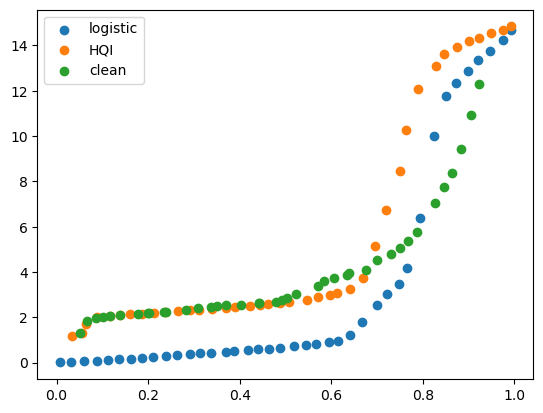

In [133]:
plt.scatter(res_df_log['cov_mean'], res_df_log['set_size_mean'], label='logistic')
plt.scatter(res_df['cov_mean'], res_df['set_size_mean'], label='HQI')
plt.scatter(res_df_train['cov_mean'], res_df_train['set_size_mean'], label='clean')
plt.legend()